# 06 · MPPI로 장애물 피하기 — 2D, 할인, warm start, 가장 좋은 후보

> 05에서 만든 MPPI를 MPC 루프에 넣어 2D 점이 장애물을 돌아가게 한다. 그 과정에서 할인 γ, warm start, "가중평균 대신 가장 좋은 후보"가 각각 어떤 문제를 푸는지, 그리고 비용만으로는 풀리지 않는 한계가 무엇인지 확인한다.

**지금 위치**

01 상태·입력·모델 → 02 비용 → 03 최적화 → 04 MPC → 05 MPPI 핵심 → **06 MPPI 장애물 회피** → 07 실전 디테일 → 08~09 로봇팔 → 10~13 프로젝트

**이 노트를 끝내면**
1. 장애물 비용이 "간격"으로 계산되고, η만큼 떨어진 곳부터 미리 켜지는 이유를 설명할 수 있다.
2. MPPI를 MPC 루프에 넣는 코드를 직접 쓰고, 후보와 가중치 그림을 읽을 수 있다.
3. 할인 γ, warm start, 가장 좋은 후보(BEST)가 각각 어떤 문제를 해결하는지 말할 수 있다.
4. soft cost와 짧은 horizon의 한계를 예로 설명할 수 있다.

**필요한 것:** [04 MPC](04_mpc.ipynb)의 receding horizon·warm start, [05 MPPI 핵심](05_mppi_core.ipynb)의 `mppi_step`·온도 β · **예상 시간:** 50분

## 복습 퀴즈

<details><summary>1. MPPI에서 후보 k의 가중치 ω_k는 비용 J_k로 어떻게 계산했나?</summary>

$\omega_k = \exp(-(J_k - \min J)/\beta) \,/\, \sum_j \exp(-(J_j - \min J)/\beta)$. 비용이 낮을수록 가중치가 크고, 가중치를 모두 더하면 1이다.
</details>

<details><summary>2. 온도 β를 크게 하면 가중치는 어떻게 바뀌나?</summary>

후보들의 가중치가 고르게 퍼진다. 그래서 새 평균이 많은 후보의 평균에 가까워진다. β가 작으면 비용이 가장 낮은 몇 개에 몰린다.
</details>

<details><summary>3. MPC는 왜 계획 전체가 아니라 첫 입력만 실행하나?</summary>

모델 오차와 외란 때문에 계획의 뒷부분은 점점 틀려진다. 매 스텝 실제 상태에서 다시 계획하면 그 오차를 보정할 수 있다.
</details>

In [1]:
import inspect
import numpy as np
from common import setup_plot, eta_cost
from course import point_rollout, point_cost, obstacle_gap, mppi_step, plot_scene_2d
plt = setup_plot()
DT2 = 0.05    # 2D 점의 시간 간격 [s]

## 1. 1D에서 2D로

### 문제
1D 카트는 레일 위에서만 움직인다. 길 한가운데 장애물이 있으면 할 수 있는 일은 멈추는 것뿐이다. **피해 가려면 옆으로 갈 수 있어야 한다.**

### 아이디어
평면 위를 움직이는 점 하나로 바꾼다. 축이 하나 늘었을 뿐 01의 카트와 똑같다.

| | 1D 카트 | 2D 점 |
|---|---|---|
| 상태 | $p, v$ (숫자 2개) | $p=(p_x,p_y),\ v=(v_x,v_y)$ (숫자 4개) |
| 입력 | 가속도 $u$ | 가속도 $u=(u_x,u_y)$ |
| 입력열 후보 `U` | `[K, T]` | `[K, T, 2]` |
| rollout 결과 | `X[K, T+1, 2]` (p, v) | `P[K, T+1, 2]`, `V[K, T+1, 2]` |

`course.point_rollout`은 01의 `cart_rollout`과 같은 등가속도 공식을 x, y 두 축에 동시에 적용한다. 코드를 직접 확인해 보자.

In [2]:
print(inspect.getsource(point_rollout))
U = np.zeros((5, 30, 2)); U[:, :, 0] = 1.0          # 후보 5개, 모두 x방향으로 1 m/s² 가속
P, V = point_rollout([0, 0], [0, 0], U, DT2)
print('U', U.shape, '→ P', P.shape, ', V', V.shape)
print('1.5초 뒤 위치:', P[0, -1].round(3), '(예상: x = 0.5·1·1.5² = 1.125)')

def point_rollout(p0, v0, U, dt=0.05):
    """2D 점: U[..., T, 2] 가속도열 -> P[..., T+1, 2], V[..., T+1, 2]."""
    U = np.asarray(U, float)
    p = np.broadcast_to(np.asarray(p0, float), U.shape[:-2] + (2,))
    v = np.broadcast_to(np.asarray(v0, float), U.shape[:-2] + (2,))
    P, V = [p], [v]
    for t in range(U.shape[-2]):
        a = U[..., t, :]
        p = p + v * dt + 0.5 * a * dt ** 2
        v = v + a * dt
        P.append(p)
        V.append(v)
    return np.stack(P, axis=-2), np.stack(V, axis=-2)

U (5, 30, 2) → P (5, 31, 2) , V (5, 31, 2)
1.5초 뒤 위치: [1.125 0.   ] (예상: x = 0.5·1·1.5² = 1.125)


## 2. 장애물을 비용으로 만들기

### 문제
02에서 비용은 "목표에서 멀수록, 힘을 많이 쓸수록" 커졌다. 이제 "장애물에 부딪히면 나쁘다"를 비용에 넣어야 한다.

먼저 떠오르는 방법은 **겹치면 큰 벌점, 아니면 0**이다. 하지만 이 방법에는 문제가 두 가지 있다.
1. 장애물을 1 mm 차이로 스치는 경로와 30 cm 떨어져 지나가는 경로가 같은 점수(0)를 받는다. 안전 여유를 줄 방법이 없다.
2. 겹치기 전까지 비용이 평평하다. 그래서 어느 쪽으로 가야 덜 위험한지 알려 주는 정보가 없다.

### 아이디어
먼저 로봇(반지름 $r_{\text{robot}}$인 원)과 장애물(반지름 $r$인 원) 표면 사이의 **간격**(gap)을 계산한다.

$$
\text{gap} = \lVert p - c\rVert - r - r_{\text{robot}}
$$

간격이 양수면 떨어져 있고, 0이면 맞닿고, 음수면 겹친다. 그리고 간격이 어떤 거리 $\eta$보다 작아지는 순간부터 **미리 비용을 켜서**, 가까워질수록 비용이 커지게 한다. 이 거리 $\eta$를 **activation distance**(비용 활성 거리)라고 부른다.

비용 모양은 `common.eta_cost`에 있다. 정확한 식은 08 노트에서 다루고, 지금은 그림으로 모양만 본다.

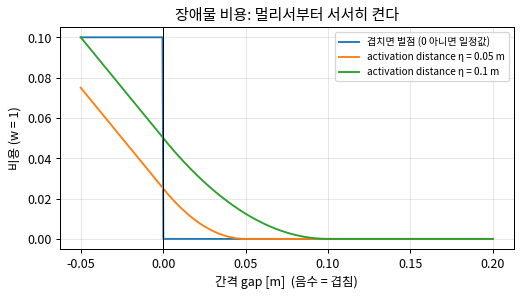

In [3]:
gap = np.linspace(-0.05, 0.2, 500)
step_penalty = np.where(gap < 0, 1.0, 0.0) * 0.1     # 겹치면 벌점
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(gap, step_penalty, label='겹치면 벌점 (0 아니면 일정값)')
for eta in [0.05, 0.1]:
    ax.plot(gap, eta_cost(gap, eta), label=f'activation distance η = {eta} m')
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('간격 gap [m]  (음수 = 겹침)'); ax.set_ylabel('비용 (w = 1)')
ax.legend(fontsize=8); ax.set_title('장애물 비용: 멀리서부터 서서히 켠다'); plt.show()

**결과 해석:** η 비용은 간격이 η보다 크면 0이고, η 안으로 들어오면 부드럽게 커진다. 겹친 뒤에는 계속 일정한 기울기로 커진다. 그래서 MPPI는 "조금 가까운 후보"와 "많이 가까운 후보"를 구별해 점수를 매길 수 있다.

이제 2D 점의 비용은 02의 항에 장애물 항을 더한 형태다 (`course.point_cost`).

$$
c_t = w_{\text{goal}}\lVert p_t - g\rVert^2 + w_{\text{obs}}\,C_\eta(\text{gap}_t) + w_u\lVert u_t\rVert^2,\qquad J = \sum_t c_t + (\text{마지막 시점의 목표·속도 항})
$$

**예측해 보기:** 원 장애물 앞에서 직접 만든 세 후보, ① 직진(장애물 관통) ② 위로 돌아가기 ③ 제자리 정지 중 비용이 가장 낮은 것은?

직진: 비용    141.3, 최소 간격 -0.190 m
우회: 비용     27.4, 최소 간격 +0.050 m
정지: 비용     50.0, 최소 간격 +0.300 m


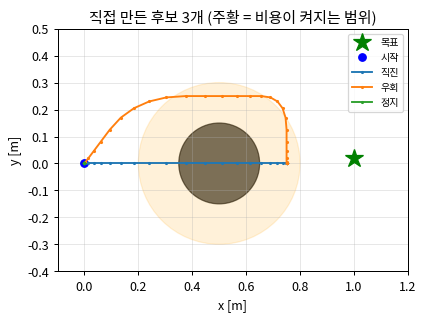

In [4]:
goal = np.array([1.0, 0.02])
obstacles = [([0.5, 0.0], 0.15)]          # (중심, 반지름)
T = 30
straight = np.zeros((T, 2)); straight[:10, 0] = 3.0; straight[10:20, 0] = -3.0
detour = straight.copy(); detour[:5, 1] = 4.0; detour[5:10, 1] = -4.0; detour[15:20, 1] = -4.0; detour[20:25, 1] = 4.0
stop = np.zeros((T, 2))
cands = np.stack([straight, detour, stop])
P, V = point_rollout([0, 0], [0, 0], cands, DT2)
J = point_cost(P, V, cands, goal, obstacles)
for name, j, g in zip(['직진', '우회', '정지'], J, obstacle_gap(P, obstacles).min(1)):
    print(f'{name}: 비용 {j:8.1f}, 최소 간격 {g:+.3f} m')

fig, ax = plt.subplots(figsize=(6, 3.5))
plot_scene_2d(ax, goal, obstacles, eta=0.1, start=(0, 0), lim=((-0.1, 1.2), (-0.4, 0.5)))
for Pk, name in zip(P, ['직진', '우회', '정지']):
    ax.plot(*Pk.T, '.-', ms=3, label=name)
ax.legend(fontsize=8); ax.set_title('직접 만든 후보 3개 (주황 = 비용이 켜지는 범위)'); plt.show()

**결과 해석:** 직진은 장애물을 관통해서 비용이 아주 크다. 우회는 직진과 같은 지점까지 가면서 장애물을 피하므로 비용이 가장 낮다. 정지는 장애물 비용은 0이지만 목표에서 계속 멀리 있어서 비용이 쌓인다. 이렇게 사람이 후보를 만들 필요 없이, MPPI가 후보 수백 개를 자동으로 만들어 이 비교를 하게 하는 것이 다음 절이다.

**한 문장으로:** "겹치면 벌점" 대신 activation distance를 쓰는 이유를 설명해 보자.

## 3. MPPI를 MPC 루프에 넣기

### 문제
05에서는 MPPI로 **한 번** 계획했다. 04에서 배웠듯이 실제로 움직이려면 매 스텝 다시 계획해야 한다(MPC).

### 아이디어
04의 MPC 루프에서 "계획" 부분을 `mppi_step`으로 바꾸면 된다. 매 스텝 다음을 반복한다.
1. 현재 상태에서 비용 함수를 만든다(rollout 시작점이 매번 바뀌므로).
2. `mppi_step`으로 평균 입력열 `mu`를 갱신한다.
3. `mu`의 첫 입력만 실행한다.
4. `mu`를 한 칸 당겨(shift) 다음 스텝의 출발점으로 쓴다. 04의 warm start와 같은 일이다.

아래 함수에는 4절과 6절에서 쓸 옵션(`gamma`, `warm`, `use_best`)이 미리 들어 있다. 지금은 기본값으로 쓴다.

In [5]:
def mppi_mpc_2d(goal, obstacles, start=(0.0, 0.0), T=30, K=400, beta=1.0, sigma=2.0, steps=80,
                gamma=1.0, warm=True, use_best=False, seed=0, u_max=4.0, snapshot_steps=()):
    rng = np.random.default_rng(seed)
    p, v = np.array(start, float), np.zeros(2)
    mu = np.zeros((T, 2))
    traj, us, snaps = [p], [], {}
    for s in range(steps):
        def cost(U):                                       # 1. 현재 상태에서 시작하는 비용
            P, V = point_rollout(p, v, U, DT2)
            return point_cost(P, V, U, goal, obstacles, gamma=gamma)
        mu, _, info = mppi_step(mu, sigma, cost, K, beta, rng, u_max=u_max)   # 2. MPPI 갱신
        if s in snapshot_steps:
            snaps[s] = dict(info, p=p.copy(), v=v.copy())
        u = info['best'][0] if use_best else mu[0]          # 3. 첫 입력만 실행
        p, v = p + v * DT2 + 0.5 * u * DT2 ** 2, v + u * DT2
        traj.append(p); us.append(u)
        mu = np.concatenate([mu[1:], mu[-1:]]) if warm else np.zeros_like(mu)   # 4. shift
    return dict(traj=np.array(traj), us=np.array(us), snaps=snaps)

def arrival_time(traj, goal, tol=0.05):
    idx = np.nonzero(np.linalg.norm(traj - goal, axis=1) < tol)[0]
    return round(idx[0] * DT2, 2) if len(idx) else None

**예측해 보기:** 목표가 아주 조금 위쪽(y = 0.02)에 있다. 점은 장애물의 위쪽과 아래쪽 중 어디로 돌아갈까?

도착 시각: 1.7 s, 최소 간격: 0.100 m


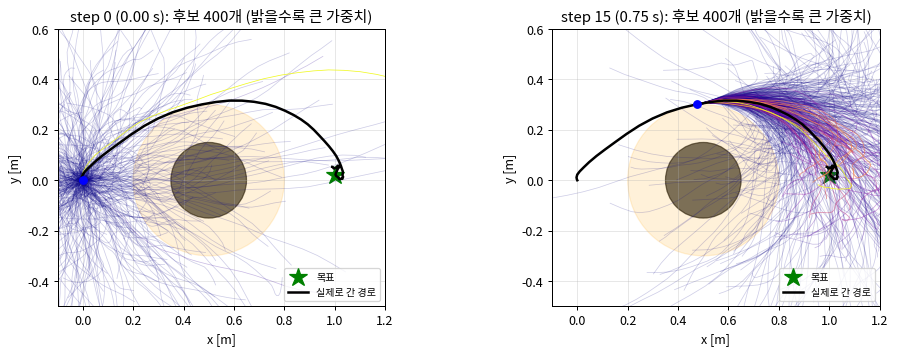

In [6]:
res = mppi_mpc_2d(goal, obstacles, steps=80, snapshot_steps=(0, 15))
tr = res['traj']
print('도착 시각: %s s, 최소 간격: %.3f m' % (arrival_time(tr, goal), obstacle_gap(tr, obstacles).min()))

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, s in zip(axs, [0, 15]):
    sn = res['snaps'][s]
    Pk, _ = point_rollout(sn['p'], sn['v'], sn['U'], DT2)
    plot_scene_2d(ax, goal, obstacles, eta=0.1, lim=((-0.1, 1.2), (-0.5, 0.6)))
    w = sn['w'] / sn['w'].max()
    for k in np.argsort(w):
        ax.plot(*Pk[k].T, color=plt.cm.plasma(w[k]), lw=0.6, alpha=0.2 + 0.8 * w[k])
    ax.plot(*tr.T, 'k-', lw=2, label='실제로 간 경로')
    ax.plot(*sn['p'], 'bo')
    ax.set_title(f'step {s} ({s * DT2:.2f} s): 후보 400개 (밝을수록 큰 가중치)'); ax.legend(fontsize=8, loc='lower right')
plt.show()

**결과 해석:**
- step 0에서는 후보가 사방으로 퍼져 있고, 장애물을 관통하는 후보는 어둡다(가중치 거의 0). 밝은 후보는 위쪽으로 돌아가는 것들이다.
- step 15에서는 평균이 이미 위쪽 우회로 옮겨 가서, 후보들도 그 주변에 모여 있다.
- 검은 선(실제 경로)은 장애물의 비용 범위(주황) 가장자리를 따라 돌아간다. 최소 간격이 대략 η(0.1 m)인 이유다. 비용이 0이 되는 거리만큼만 떨어지면 더 멀리 갈 이유가 없다.

**직접 해보기:** `goal`을 `[1.0, -0.02]`로 바꿔 다시 실행해 보자.
<details><summary>예상 결과</summary>

이번에는 아래쪽으로 돌아갈 가능성이 크다. 목표가 아래에 있으면 아래 우회가 조금 더 싸기 때문이다. 다만 샘플링이라 seed에 따라 달라질 수 있다.
</details>

## 4. 할인 γ — 먼 미래를 얼마나 믿을까

### 문제
04에서 본 것처럼 모델은 근사라서, 먼 미래일수록 예측이 틀릴 가능성이 크다. 그런데 지금 비용은 1초 뒤의 비용과 0.05초 뒤의 비용을 똑같이 센다.

### 아이디어
$t$번째 시점의 비용에 $\gamma^t$($0<\gamma\le1$)를 곱해서, 먼 미래 비용을 조금씩 덜 반영한다. 이 $\gamma$를 **할인율**(discount factor)이라고 한다.

$$
J = \sum_{t=0}^{T-1} \gamma^t\, c_t
$$

$\gamma=0.98$이면 $t=29$일 때 $0.98^{29}\approx0.56$이다. 마지막 시점 비용을 약 절반만 센다.

**예측해 보기:** γ를 0.8까지 줄이면 도착이 빨라질까, 느려질까? 마지막 시점에 들어 있는 "목표에 도착하라"는 항도 함께 할인된다는 점을 생각해 보자.

γ = 1.00: 도착 시각 1.7 s, 최소 간격 0.100 m, 5초 뒤 목표 오차 0.022 m
γ = 0.98: 도착 시각 1.8 s, 최소 간격 0.102 m, 5초 뒤 목표 오차 0.017 m
γ = 0.90: 도착 시각 None s, 최소 간격 0.114 m, 5초 뒤 목표 오차 0.050 m
γ = 0.80: 도착 시각 None s, 최소 간격 0.155 m, 5초 뒤 목표 오차 0.206 m


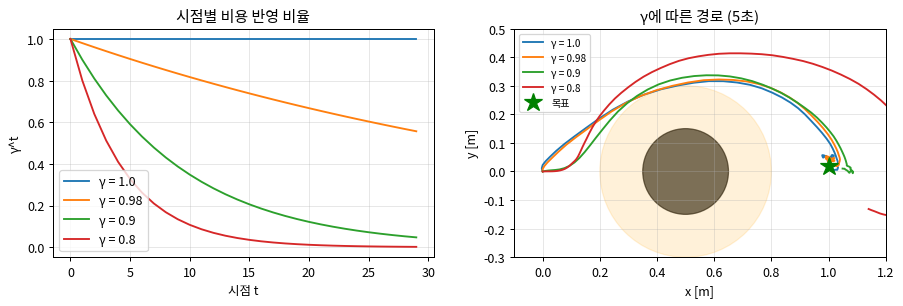

In [7]:
t = np.arange(T)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.3))
for g in [1.0, 0.98, 0.9, 0.8]:
    axs[0].plot(t, g ** t, label=f'γ = {g}')
    r = mppi_mpc_2d(goal, obstacles, gamma=g, steps=100)
    axs[1].plot(*r['traj'].T, label=f'γ = {g}')
    print('γ = %.2f: 도착 시각 %s s, 최소 간격 %.3f m, 5초 뒤 목표 오차 %.3f m' % (
        g, arrival_time(r['traj'], goal), obstacle_gap(r['traj'], obstacles).min(), np.linalg.norm(r['traj'][-1] - goal)))
axs[0].set_xlabel('시점 t'); axs[0].set_ylabel('γ^t'); axs[0].legend(); axs[0].set_title('시점별 비용 반영 비율')
plot_scene_2d(axs[1], goal, obstacles, eta=0.1, lim=((-0.1, 1.2), (-0.3, 0.5))); axs[1].legend(fontsize=8)
axs[1].set_title('γ에 따른 경로 (5초)')
plt.show()

**결과 해석:** γ=0.98은 γ=1과 거의 같게 움직인다. γ를 0.9, 0.8로 줄이면 5초 안에 목표(오차 5 cm 이내)에 도착하지 못한다. 목표로 끌어당기는 비용, 특히 마지막 시점의 큰 목표 항이 많이 할인되기 때문이다. 반대로 장애물과는 더 멀리 떨어진다. 가까운 시점의 장애물 비용은 할인이 거의 없어서 상대적으로 크게 보이기 때문이다.

할인은 "먼 미래를 덜 믿는" 장치지만, 너무 줄이면 목표를 향한 당김까지 약해진다. 로봇에서는 보통 1에 가까운 값(cuRobo는 0.98)을 쓴다.

## 5. warm start — 매번 0부터 시작하면

### 문제
04에서 warm start는 계산을 줄이는 장치였다. MPPI에서는 이것이 더 중요하다. MPPI는 한 스텝에 갱신을 몇 번만 한다(여기서는 1번, cuRobo는 5번). 매번 평균을 0(아무것도 안 하기)에서 시작하면, 몇 번의 갱신으로는 좋은 계획까지 가지 못한다.

**예측해 보기:** warm start를 끄면(`warm=False`, 매 스텝 평균을 0으로 초기화) 도착 시각은 어떻게 될까?

warm start True : 도착 시각 1.7 s
warm start False: 도착 시각 2.95 s


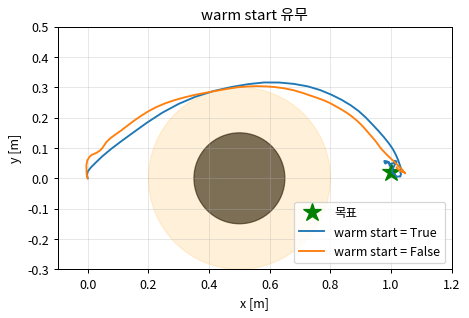

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
plot_scene_2d(ax, goal, obstacles, eta=0.1, lim=((-0.1, 1.2), (-0.3, 0.5)))
for warm in [True, False]:
    r = mppi_mpc_2d(goal, obstacles, warm=warm, steps=100)
    ax.plot(*r['traj'].T, label=f'warm start = {warm}')
    print('warm start %-5s: 도착 시각 %s s' % (warm, arrival_time(r['traj'], goal)))
ax.legend(); ax.set_title('warm start 유무'); plt.show()

**결과 해석:** warm start가 없으면 도착이 훨씬 늦다. 매 스텝 "정지"에 가까운 평균에서 한 번만 갱신하므로, 명령이 매번 소극적이 된다. 직전 계획을 한 칸 당겨서 시작하면 지난 스텝까지 쌓은 개선을 이어 갈 수 있다.

## 6. 가중평균 vs 가장 좋은 후보

### 문제
05에서 MPPI의 새 계획은 후보들의 **가중평균**이었다. 그런데 좋은 후보들이 서로 다른 두 무리로 나뉘면 어떻게 될까?

목표가 장애물 바로 뒤 정중앙(y=0)에 있으면 위로 돌아가는 후보와 아래로 돌아가는 후보가 비슷하게 좋다. 둘을 평균하면 위아래가 상쇄되어 **가운데, 즉 장애물 쪽**으로 가는 계획이 나올 수 있다.

**예측해 보기:** 아래 셀은 정지 상태에서 MPPI를 한 번 갱신하고 ① 가중평균 계획과 ② 가중치가 가장 큰 단일 후보를 각각 rollout한다. 어느 쪽이 장애물에 부딪힐까?

가중치 합: 위쪽 후보 0.62, 아래쪽 후보 0.38
가중평균 계획의 최소 간격 -0.112 m | 가장 좋은 후보의 최소 간격 +0.116 m


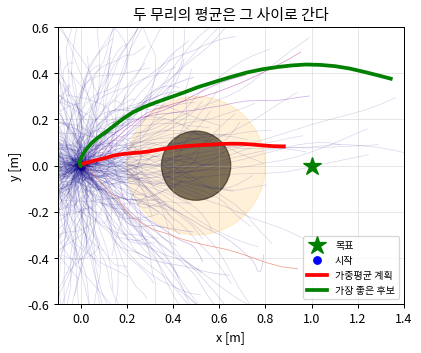

In [9]:
goal_c = np.array([1.0, 0.0])                       # 장애물 정중앙 뒤
rng = np.random.default_rng(0)
p0, v0 = np.zeros(2), np.zeros(2)
cost0 = lambda U: point_cost(*point_rollout(p0, v0, U, DT2), U, goal_c, obstacles)
mu_new, _, info = mppi_step(np.zeros((T, 2)), 2.0, cost0, 400, 3.0, rng, u_max=4.0)   # β = 3

Pk, _ = point_rollout(p0, v0, info['U'], DT2)
P_mean, _ = point_rollout(p0, v0, mu_new, DT2)
P_best, _ = point_rollout(p0, v0, info['best'], DT2)
up = Pk[:, -1, 1] > 0
print('가중치 합: 위쪽 후보 %.2f, 아래쪽 후보 %.2f' % (info['w'][up].sum(), info['w'][~up].sum()))
print('가중평균 계획의 최소 간격 %+.3f m | 가장 좋은 후보의 최소 간격 %+.3f m' % (
    obstacle_gap(P_mean, obstacles).min(), obstacle_gap(P_best, obstacles).min()))

fig, ax = plt.subplots(figsize=(6.5, 4))
plot_scene_2d(ax, goal_c, obstacles, eta=0.1, start=p0, lim=((-0.1, 1.4), (-0.6, 0.6)))
w = info['w'] / info['w'].max()
for k in np.argsort(w):
    ax.plot(*Pk[k].T, color=plt.cm.plasma(w[k]), lw=0.6, alpha=0.15 + 0.85 * w[k])
ax.plot(*P_mean.T, 'r-', lw=3, label='가중평균 계획')
ax.plot(*P_best.T, 'g-', lw=3, label='가장 좋은 후보')
ax.legend(fontsize=8, loc='lower right'); ax.set_title('두 무리의 평균은 그 사이로 간다'); plt.show()

**결과 해석:** 가중치가 위쪽과 아래쪽 후보에 나뉘어 실렸다. 그 결과 가중평균 계획은 위아래 우회가 섞여 장애물을 파고든다(최소 간격이 음수). 가중치가 가장 큰 단일 후보는 실제로 비용을 계산해 본 경로라서 장애물을 피한다.

그래서 실전에서는 이렇게 역할을 나눈다.
- **실제 명령**: 가중치가 가장 큰 단일 후보(가장 좋은 후보). cuRobo에서는 이 방식을 `sample_mode: BEST`라고 부른다.
- **다음 탐색의 중심**: 가중평균 `mu`. 여러 좋은 후보의 정보를 모아 다음 샘플링의 중심을 옮긴다.

β 값과 MPC 루프 전체에서도 확인해 본다. 루프에서는 첫 스텝 뒤에 대칭이 금방 깨지기 때문에, β가 작으면 두 방식의 차이가 작다. β가 커서 가중치가 넓게 퍼질수록 평균의 문제가 커진다.

In [10]:
for beta in [1.0, 10.0]:
    for use_best in [False, True]:
        r = mppi_mpc_2d(goal_c, obstacles, beta=beta, use_best=use_best, steps=80)
        tr = r['traj']
        print('β=%4.1f %-12s: 4초 뒤 목표 오차 %.3f m, 최소 간격 %+.3f m' % (
            beta, '가장 좋은 후보' if use_best else '가중평균', np.linalg.norm(tr[-1] - goal_c), obstacle_gap(tr, obstacles).min()))

β= 1.0 가중평균        : 4초 뒤 목표 오차 0.034 m, 최소 간격 +0.100 m
β= 1.0 가장 좋은 후보    : 4초 뒤 목표 오차 0.030 m, 최소 간격 +0.108 m
β=10.0 가중평균        : 4초 뒤 목표 오차 0.112 m, 최소 간격 +0.136 m
β=10.0 가장 좋은 후보    : 4초 뒤 목표 오차 0.018 m, 최소 간격 +0.149 m


**결과 해석:** β=1에서는 두 방식 모두 잘 도착한다. β=10에서는 가중평균 방식이 4초 안에 목표에 도착하지 못한다. 가중치가 넓게 퍼지면 서로 다른 방향의 후보가 많이 섞여서, 평균 명령이 어느 쪽으로도 확실히 가지 않는 소극적인 명령이 된다. 가장 좋은 후보 방식은 같은 β에서도 잘 도착한다.

**한 문장으로:** 실제 명령에는 가장 좋은 후보를 쓰고 탐색 중심에는 가중평균을 쓰는 이유를 설명해 보자.

## 7. soft cost의 한계 — 모든 후보가 부딪히면

### 문제
장애물 비용이 아무리 커도 그것은 **점수**일 뿐이다. 후보를 지우는 규칙(제약)이 아니다. 그렇다면 모든 후보가 부딪히는 상황에서는 어떻게 될까?

### 아이디어
장애물 바로 앞에서 장애물 쪽으로 2 m/s로 달리는 상태를 만든다. 가속도 한계(4 m/s²) 때문에 어떤 후보도 제때 멈추거나 비킬 수 없다. 장애물 비용 가중치도 100000으로 아주 크게 둔다.

In [11]:
p_fast, v_fast = np.array([0.22, 0.0]), np.array([2.0, 0.0])
cost_fast = lambda U: point_cost(*point_rollout(p_fast, v_fast, U, DT2), U, goal_c, obstacles, w_obs=1e5)
_, _, info = mppi_step(np.zeros((T, 2)), 2.0, cost_fast, 400, 1.0, np.random.default_rng(0), u_max=4.0)
Pk, _ = point_rollout(p_fast, v_fast, info['U'], DT2)
gaps = obstacle_gap(Pk, obstacles).min(1)
print('부딪히는 후보: %d / 400' % (gaps < 0).sum())
print('가중치 합 = %.3f, 가장 큰 가중치 = %.3f' % (info['w'].sum(), info['w'].max()))
print('선택된 후보의 최소 간격: %+.3f m (모든 후보 중 가장 덜 겹치는 값: %+.3f m)' % (gaps[np.argmax(info['w'])], gaps.max()))

부딪히는 후보: 400 / 400
가중치 합 = 1.000, 가장 큰 가중치 = 1.000
선택된 후보의 최소 간격: -0.141 m (모든 후보 중 가장 덜 겹치는 값: -0.141 m)


**결과 해석:** 400개 모두 부딪히는데도 가중치의 합은 1이고, 그중 하나가 선택된다. MPPI는 "덜 나쁜" 후보를 고를 뿐, 안전한 후보가 없다는 사실을 알려 주지 않는다. 이렇게 비용으로만 표현하는 방식을 **soft cost**(부드러운 비용)라고 부른다. 반대로 위반을 절대 허용하지 않는 규칙은 **hard constraint**(강한 제약)라고 한다.

그래서 실제 로봇에서는 비용과 별도로 안전 장치(정지 판단, 속도 제한 등)가 필요하다. 이 프로젝트의 결과를 읽을 때도 "비용을 크게 줬으니 안전하다"고 해석하면 안 된다(12 노트).

## 8. 넓은 벽과 horizon 길이

### 문제
03에서는 경사하강이 출발점에 따라 웅덩이 앞 골짜기(국소 최솟값)에 갇히는 것을 봤고, 04에서는 horizon이 짧으면 미리 대비하지 못한다는 것을 봤다. 장애물이 넓어서 길을 막으면, 돌아가는 길은 처음에 목표에서 **멀어지는** 경로다. horizon이 짧으면 그 멀어지는 구간만 보여서 우회가 정지보다 비싸 보일 수 있다. 샘플링을 쓰는 MPPI라면 다를까?

### 아이디어
목표 앞을 넓은 벽이 막고 있다. 벽의 위쪽 끝이나 아래쪽 끝으로 돌아가야 하고, 위쪽이 조금 더 가깝다. horizon $T$를 바꿔 가며 같은 MPPI-MPC를 돌린다.

**예측해 보기:** T=10(0.5초)과 T=40(2초) 중 어느 쪽이 벽을 돌아갈까?

T=10 (0.5 s): 10초 뒤 목표 오차 0.713 m → 벽 앞에서 멈춤
T=20 (1.0 s): 10초 뒤 목표 오차 0.734 m → 벽 앞에서 멈춤
T=40 (2.0 s): 10초 뒤 목표 오차 0.022 m → 돌아감
T=60 (3.0 s): 10초 뒤 목표 오차 0.022 m → 돌아감


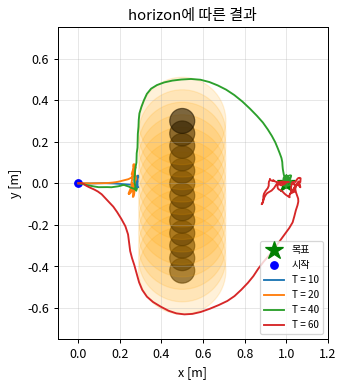

In [12]:
wall = [([0.5, y], 0.06) for y in np.arange(-0.42, 0.31, 0.06)]
goal_w = np.array([1.0, 0.0])
fig, ax = plt.subplots(figsize=(6.5, 4.5))
plot_scene_2d(ax, goal_w, wall, eta=0.1, start=(0, 0), lim=((-0.1, 1.2), (-0.75, 0.75)))
for Tw in [10, 20, 40, 60]:
    r = mppi_mpc_2d(goal_w, wall, T=Tw, sigma=1.0, steps=200)
    tr = r['traj']
    err = np.linalg.norm(tr[-1] - goal_w)
    print('T=%2d (%.1f s): 10초 뒤 목표 오차 %.3f m → %s' % (Tw, Tw * DT2, err, '돌아감' if err < 0.1 else '벽 앞에서 멈춤'))
    ax.plot(*tr.T, label=f'T = {Tw}')
ax.legend(fontsize=8, loc='lower right'); ax.set_title('horizon에 따른 결과'); plt.show()

**결과 해석:** T=10, 20은 벽 앞에서 멈춘다. T=40, 60은 벽을 돌아 목표에 도착한다(이 실행에서는 T=40이 위쪽, T=60이 아래쪽으로 돌았다. 어느 쪽으로 돌지는 샘플에 따라 달라진다). 짧은 horizon 안에서는 돌아가는 후보가 처음에 목표에서 멀어지는 구간만 보여서 비용이 크다. 그래서 샘플링으로 그런 후보를 **찾아도 선택되지 않는다.** horizon이 우회의 이득(목표 접근)이 보일 만큼 길어야 우회가 가장 싼 후보가 된다.

다만 이것은 장면 하나, seed 하나의 결과다. horizon을 길게 하면 계산량이 늘고(후보마다 더 많은 시점을 rollout), 모델 오차가 쌓인 먼 미래까지 믿게 된다. 이 절충 때문에 로봇에서는 horizon을 무한정 늘리지 않는다.

## 핵심 정리

- 장애물 비용은 **간격**(gap)으로 계산하고, activation distance η 안으로 들어올 때부터 미리 켠다.
- MPPI-MPC 루프: 현재 상태에서 비용 정의 → `mppi_step` → 첫 입력 실행 → 평균 shift(warm start).
- **할인 γ**는 먼 미래 비용을 덜 센다. 너무 작으면 목표로의 당김도 약해진다.
- 좋은 후보가 두 무리로 나뉘면 가중평균은 그 사이(장애물)로 갈 수 있다. 그래서 명령은 **가장 좋은 후보**, 탐색 중심은 가중평균으로 쓴다.
- 비용은 soft cost다. 모든 후보가 나쁘면 덜 나쁜 것을 고를 뿐이다. horizon이 짧으면 우회를 찾아도 선택하지 않는다.

`mppi_mpc_2d`와 `arrival_time`은 `lab2d.py`에 같은 코드로 저장해 두었다(07 노트에서 쓸 옵션 몇 개를 더했다).

## 확인 문제

<details><summary>1. 간격이 0.2 m이고 η = 0.1 m면 장애물 비용은? 간격이 0.05 m면?</summary>

0.2 m는 η보다 멀어서 비용 0. 0.05 m는 η 안이라 비용이 양수다(가까울수록 커진다).
</details>

<details><summary>2. 3절에서 실제 경로의 최소 간격이 대략 η 근처였던 이유는?</summary>

η보다 멀어지면 장애물 비용이 0이라 더 멀리 돌아갈 이득이 없다. 목표 비용은 짧게 갈수록 줄어드니, 비용이 막 켜지는 경계 근처를 따라간다.
</details>

<details><summary>3. γ = 0.98, T = 30일 때 마지막 시점 비용은 몇 % 반영되나?</summary>

$0.98^{29} \approx 0.56$, 약 56%.
</details>

<details><summary>4. 가중평균 계획이 장애물을 파고들 수 있는 상황을 설명하면?</summary>

좋은 후보가 위쪽 우회와 아래쪽 우회처럼 서로 다른 무리로 나뉘고 가중치도 둘에 나뉘어 실릴 때. 평균은 두 경로의 중간, 즉 장애물을 지나는 경로가 된다.
</details>

<details><summary>5. 장애물 비용 가중치를 100배로 키우면 충돌을 막을 수 있나?</summary>

보장할 수 없다. 모든 후보가 부딪히면 그래도 하나가 선택된다(7절). 비용은 순위를 매길 뿐 후보를 지우지 않는다.
</details>

## 실제 프로젝트에서는

| 이 노트 | cuRobo / franka-depth-mppi |
|---|---|
| 2D 점 원 장애물, 간격 | 로봇팔을 덮는 충돌 구 61개와 장애물(깊이 지도·손 관측점) 사이 간격 (08~11 노트) |
| activation distance η = 0.1 m | 환경 충돌 비용 η = 0.025 m. 손 전용 비용 η = 25 / 73.52 mm (11 노트) |
| 장애물 가중치 100 / 100000 | `primitive_collision_cfg.weight: 100000` (soft cost) |
| 할인 γ | `particle_mpc.yml`의 `gamma: 0.98` |
| 가장 좋은 후보로 명령 | `sample_mode: 'BEST'` (`curobo/opt/particle/parallel_mppi.py:295-298`) |
| horizon T = 30 | horizon 30스텝 ≈ 0.675 s (09 노트) |

## 다음 노트

[07 · 실전 MPPI의 디테일](07_mppi_details.ipynb): 여기까지가 MPPI의 뼈대다. 실제 로봇에 쓰면 명령이 떨리거나, 실행할 때마다 결과가 달라지거나, 탐색 폭이 무너지는 문제가 생긴다. cuRobo 설정 파일에 있는 여러 장치가 각각 어떤 문제를 푸는지 하나씩 본다.